In [ ]:
#Import Library
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)


In [ ]:
# 1. Load Datset Sintetis
df = pd.read_csv("dataset_churn_sederhana.csv")
X = df.drop(columns="churn")
y = df["churn"]          # 1 = churn, 0 = bertahan
df


,lama_berlangganan_bulan,jumlah_keluhan,hari_sejak_login_terakhir,kontrak_tahunan,churn
0,7,1,17,1,1
1,11,1,11,0,1
2,29,2,12,1,0
3,8,1,6,1,1
4,16,1,5,0,1
...,...,...,...,...,...
495,42,0,1,0,0
496,12,0,5,0,1
497,2,0,5,1,0
498,20,0,29,0,1


In [ ]:
# 2. Bagi data: 80% data latih, 20% data uji
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)


In [ ]:
# 3. Latih model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)


LogisticRegression(max_iter=1000)

In [ ]:
# 4. Evaluasi
pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]
print(f"Akurasi  : {accuracy_score(y_test, pred):.2f}")
print(f"Precision: {precision_score(y_test, pred):.2f}")
print(f"Recall   : {recall_score(y_test, pred):.2f}")
print(f"F1-score : {f1_score(y_test, pred):.2f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, proba):.2f}")

Akurasi  : 0.85
Precision: 0.85
Recall   : 0.80
F1-score : 0.82
ROC-AUC  : 0.94


In [ ]:
# 5. Persamaan model
print("\nlog-odds = {:.2f}".format(model.intercept_[0]), end="")
for nama, k in zip(X.columns, model.coef_[0]):
    print(f" {k:+.2f} x {nama}", end="")
print("\n")


log-odds = 0.00 -0.14 x lama_berlangganan_bulan +1.64 x jumlah_keluhan +0.12 x hari_sejak_login_terakhir -2.84 x kontrak_tahunan



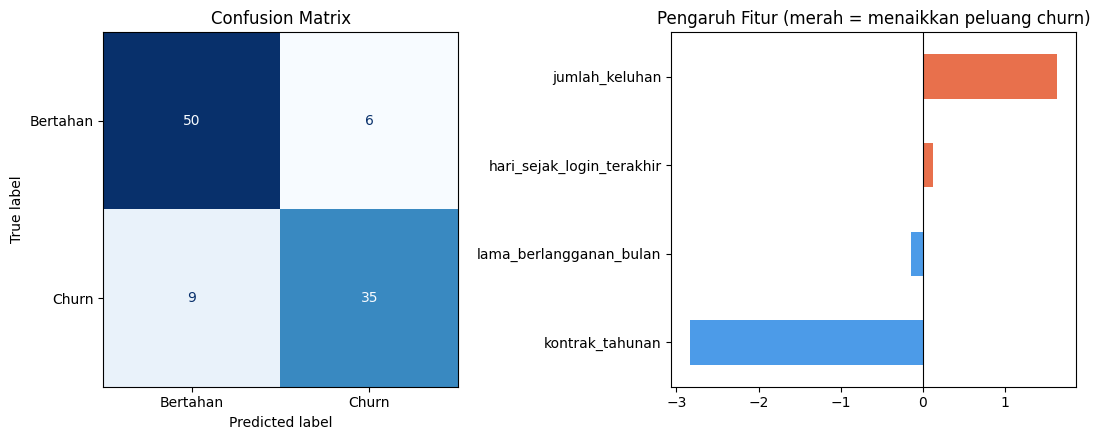

In [ ]:
# 6. Grafik: confusion matrix + pengaruh fitur
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=["Bertahan", "Churn"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion Matrix")
koef = pd.Series(model.coef_[0], index=X.columns).sort_values()
koef.plot(kind="barh", ax=ax[1], color=["#e8704c" if v > 0 else "#4c9be8" for v in koef])
ax[1].axvline(0, color="k", lw=.8)
ax[1].set_title("Pengaruh Fitur (merah = menaikkan peluang churn)")
plt.tight_layout()

In [ ]:
# 7. Prediksi Churn/tidak churn kalau ada pelanggan baru
baru = pd.DataFrame({
    "lama_berlangganan_bulan": [6, 30, 12],
    "jumlah_keluhan": [3, 0, 1],
    "hari_sejak_login_terakhir": [25, 5, 10],
    "kontrak_tahunan": [0, 1, 0],
})
baru["peluang_churn"] = model.predict_proba(baru)[:, 1].round(2)
baru["prediksi"] = baru["peluang_churn"].apply(lambda p: "Churn" if p >= 0.5 else "Bertahan")
print(baru.to_string(index=False))

 lama_berlangganan_bulan  jumlah_keluhan  hari_sejak_login_terakhir  kontrak_tahunan  peluang_churn prediksi
                       6               3                         25                0           1.00    Churn
                      30               0                          5                1           0.00 Bertahan
                      12               1                         10                0           0.77    Churn
